<a href="https://colab.research.google.com/github/susenaratne-pixel/6BUIS017W-CWK1-RFM/blob/main/CWK1_RFM_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CW1: Market Analysis and Stock Segmentation Using RFM
Sandasi Senaratne / 20232030 / w2054071
GitHub: https://github.com/susenaratne-pixel/6BUIS017W-CWK1-RFM


To rerun: Run all. Saved data in /data is used, so results reproduce exactly.

In [34]:
import os
if not os.path.exists("data"):
    !git clone https://github.com/susenaratne-pixel/6BUIS017W-CWK1-RFM.git repo
    %cd repo

## Task 1.1: Ticker selection and data acquisition

Setup : First I install and import everything needed. I also set the study period here: 1 January 2021 up to 1 January 2025. The printed package versions mean anyone rerunning this knows exactly what I used.

In [35]:
!pip install -q yfinance lxml
import os, io, json, time, platform, datetime as dt
import numpy as np, pandas as pd, requests, yfinance as yf
import matplotlib, matplotlib.pyplot as plt, sklearn, scipy
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

START, END, BENCH = "2021-01-01", "2025-01-01", "^GSPC"   # END is exclusive
os.makedirs("data", exist_ok=True); os.makedirs("outputs", exist_ok=True)
print({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "yfinance": yf.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__})

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'scikit-learn': '1.6.1', 'scipy': '1.16.3'}


Getting the S&P 500 list: This pulls the current list of S&P 500 companies from Wikipedia and saves it with the date I retrieved it. Yahoo writes tickers like BRK.B as BRK-B, so I convert those so the download doesn't fail.

In [36]:
if os.path.exists("data/sp500_constituents.csv"):
    sp500 = pd.read_csv("data/sp500_constituents.csv")
    retrieved = json.load(open("data/metadata.json"))["retrieved"]
    print("Using saved ticker snapshot retrieved", retrieved)
else:
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (student coursework)"}, timeout=30).text
    sp500 = pd.read_html(io.StringIO(html))[0]
    sp500["yf_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)
    retrieved = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    sp500.to_csv("data/sp500_constituents.csv", index=False)
    json.dump({"ticker_source": url, "retrieved": retrieved, "start": START, "end_exclusive": END},
              open("data/metadata.json", "w"), indent=2)
print(len(sp500), "tickers, retrieved", retrieved)

Using saved ticker snapshot retrieved 2026-11-23 12:55 UTC
503 tickers, retrieved 2026-11-23 12:55 UTC


Downloading prices: Here I download daily prices, volume, splits and dividends for every company, plus the S&P 500 index itself (^GSPC). I chose yfinance because it's free, well documented and works easily in Colab. I download in batches of 100 so Yahoo doesn't block the requests, and I keep both the raw Close and the Adjusted Close because I need each for different calculations. Everything is saved straight to CSV.

In [37]:
tickers = sp500["yf_ticker"].tolist()

if not os.path.exists("data/daily_adj_close.csv"):
    parts = []
    for i in range(0, len(tickers), 100):
        print(f"Downloading {i+1}–{min(i+100, len(tickers))} of {len(tickers)}...")
        parts.append(yf.download(tickers[i:i+100], start=START, end=END, auto_adjust=False,
                                 actions=True, group_by="column", progress=False))
        time.sleep(2)
    raw = pd.concat(parts, axis=1)
    for f in ["Close", "Adj Close", "Volume", "Stock Splits", "Dividends"]:
        if f in raw.columns.get_level_values(0):
            raw[f].to_csv(f"data/daily_{f.replace(' ', '_').lower()}.csv")
    bench = yf.download(BENCH, start=START, end=END, auto_adjust=False, progress=False)
    if isinstance(bench.columns, pd.MultiIndex):
        bench.columns = bench.columns.get_level_values(0)
    bench.to_csv("data/benchmark_gspc.csv")
    print("Done. Shares downloaded:", raw["Adj Close"].notna().any().sum(), "| Benchmark rows:", len(bench))
else:
    print("Using saved price snapshot in /data (no download).")

Using saved price snapshot in /data (no download).


In [38]:
!zip -r data_backup.zip data
from google.colab import files
files.download("data_backup.zip")

updating: data/ (stored 0%)
updating: data/metadata.json (deflated 21%)
updating: data/sp500_constituents.csv (deflated 68%)
updating: data/daily_close.csv (deflated 77%)
updating: data/daily_volume.csv (deflated 62%)
updating: data/daily_stock_splits.csv (deflated 99%)
updating: data/benchmark_gspc.csv (deflated 77%)
updating: data/daily_adj_close.csv (deflated 62%)
updating: data/daily_dividends.csv (deflated 98%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading the saved data: From here on I work from the saved files rather than downloading again. That way my results stay the same even if Yahoo updates its data and ayone can rerun everything without waiting for a download.

In [39]:
rd = lambda f: pd.read_csv(f, index_col=0, parse_dates=True)
close, adj, vol = rd("data/daily_close.csv"), rd("data/daily_adj_close.csv"), rd("data/daily_volume.csv")
splits = rd("data/daily_stock_splits.csv") if os.path.exists("data/daily_stock_splits.csv") else pd.DataFrame()
bench = rd("data/benchmark_gspc.csv")

## Task 1.2: Data validation and alignment

Checking the data: Before doing any calculations, I check each share for problems: duplicate dates, missing values, zero or negative prices, zero-volume days, and gaps at the start or end of its history. Any share with a problem is removed, not patched, and the reason is recorded. I also flag stock splits and any day the price moved more than 40%, in case a split wasn't adjusted properly.

In [40]:
cal = bench.index[bench["Adj Close"].notna()]          # benchmark trading calendar
print("Duplicate dates (shares, benchmark):", adj.index.duplicated().sum(), bench.index.duplicated().sum())
log = []
for t in tickers:
    if t not in adj.columns or adj[t].notna().sum() == 0:
        log.append({"ticker": t, "status": "excluded", "reason": "no data downloaded"}); continue
    a, c, v = adj[t].reindex(cal), close[t].reindex(cal), vol[t].reindex(cal)
    reasons = []
    if a.first_valid_index() > cal[0]: reasons.append(f"history starts {a.first_valid_index().date()}")
    if a.last_valid_index() < cal[-1]: reasons.append(f"history ends {a.last_valid_index().date()}")
    if not reasons and (a.isna().any() or c.isna().any() or v.isna().any()): reasons.append("missing values")
    if (a <= 0).any() or (c <= 0).any(): reasons.append("non-positive price")
    if (v <= 0).any(): reasons.append("zero/negative volume")
    log.append({"ticker": t, "status": "excluded" if reasons else "included", "reason": "; ".join(reasons),
                "n_splits": int((splits[t].fillna(0) > 0).sum()) if t in splits.columns else 0,
                "close_moves_over_40pct": int((c.pct_change(fill_method=None).abs() > 0.4).sum())})
log = pd.DataFrame(log)
log.to_csv("outputs/inclusion_exclusion_log.csv", index=False)
print(log["status"].value_counts())
log[log.status == "excluded"]

Duplicate dates (shares, benchmark): 0 0
status
included    486
excluded     17
Name: count, dtype: int64


,ticker,status,reason,n_splits,close_moves_over_40pct
40,APP,excluded,history starts 2021-04-15,0.0,1.0
116,COIN,excluded,history starts 2021-04-14,0.0,0.0
123,CEG,excluded,history starts 2022-01-19,0.0,0.0
181,EXE,excluded,history starts 2021-02-10,0.0,0.0
192,FDXF,excluded,no data downloaded,NaN,NaN
193,FERG,excluded,zero/negative volume,0.0,0.0
210,GEHC,excluded,history starts 2022-12-15,0.0,0.0
211,GEV,excluded,history starts 2024-03-27,0.0,0.0
233,HONA,excluded,no data downloaded,NaN,NaN
379,Q,excluded,no data downloaded,NaN,NaN


Check 1: why FERG and SW have zero volume.

In [41]:
for t in ["FERG", "SW"]:
    v = vol[t].reindex(cal)
    print(t, "| zero-volume days:", int((v == 0).sum()),
          "| first day with real volume:", v[v > 0].index.min().date())

FERG | zero-volume days: 27 | first day with real volume: 2021-01-04
SW | zero-volume days: 424 | first day with real volume: 2021-01-04


Check 2: the included shares.

In [42]:
flagged = log[(log.status == "included") & ((log.n_splits > 0) | (log.close_moves_over_40pct > 0))]
print(len(flagged), "included shares with splits or >40% daily moves")
flagged

56 included shares with splits or >40% daily moves


,ticker,status,reason,n_splits,close_moves_over_40pct
0,MMM,included,,1.0,0.0
19,GOOGL,included,,1.0,0.0
20,GOOG,included,,1.0,0.0
22,AMZN,included,,1.0,0.0
33,APH,included,,2.0,0.0
45,ANET,included,,2.0,0.0
48,T,included,,1.0,0.0
59,BDX,included,,1.0,0.0
62,TECH,included,,1.0,0.0
67,BE,included,,0.0,1.0


In [43]:
for t in ["CVNA", "BE", "DXCM", "GL"]:
    r = close[t].reindex(cal).pct_change(fill_method=None)
    big = r[r.abs() > 0.4]
    split_dates = splits[t][splits[t].fillna(0) > 0].index if t in splits.columns else []
    for d, x in big.items():
        print(f"{t} {d.date()}: {x:+.1%} | split on same day: {d in split_dates}")

CVNA 2022-08-05: +40.1% | split on same day: False
CVNA 2022-12-07: -42.9% | split on same day: False
CVNA 2023-01-12: +46.0% | split on same day: False
CVNA 2023-06-08: +56.0% | split on same day: False
CVNA 2023-07-19: +40.2% | split on same day: False
BE 2024-11-15: +59.2% | split on same day: False
DXCM 2024-07-26: -40.7% | split on same day: False
GL 2024-04-11: -53.1% | split on same day: False


## Task 1.3: Weekly return and weekly beta

Weekly returns and beta: I convert daily prices into weekly prices using the last price of each week ending on Friday. Incomplete weeks at the start and end are dropped, but normal holiday weeks are kept. The weekly return compares each week's price with the week before. From this, I calculate each share's average weekly return and its beta, which shows how closely it moves with the market. Checks confirm that no weeks are missing and that share and index weeks line up. I also verify beta with a simple regression.

In [44]:
inc = log.loc[log.status == "included", "ticker"].tolist()
adj_c, bench_c = adj[inc].reindex(cal), bench["Adj Close"].reindex(cal)
days = pd.Series(1, index=cal).resample("W-FRI").sum()
mondays = days.index - pd.Timedelta(days=4)
keep = days.index[(mondays >= START) & (days.index < END) & (days > 0)]   # full Mon–Fri inside study period
print("Dropped incomplete boundary weeks:", list(days.index.difference(keep).date))
print("Holiday-shortened weeks retained:", int((days.loc[keep] < 5).sum()))
w_px = adj_c.resample("W-FRI").last().loc[keep]
w_bx = bench_c.resample("W-FRI").last().loc[keep]
assert (pd.Series(keep).diff().dropna() == pd.Timedelta(days=7)).all()   # no multi-week gaps
w_ret, w_bret = w_px.pct_change(fill_method=None).iloc[1:], w_bx.pct_change(fill_method=None).iloc[1:]
assert w_ret.index.equals(w_bret.index)                                   # identical week labels
mean_ret = w_ret.mean()
beta = w_ret.apply(lambda s: s.cov(w_bret) / w_bret.var())
n_weeks = w_ret.notna().sum()
print("Aligned weekly observations:", n_weeks.min(), "-", n_weeks.max())
print("Independent check (AAPL regression slope vs beta):", np.polyfit(w_bret, w_ret["AAPL"], 1)[0], beta["AAPL"])

Dropped incomplete boundary weeks: [datetime.date(2025, 1, 3)]
Holiday-shortened weeks retained: 37
Aligned weekly observations: 207 - 207
Independent check (AAPL regression slope vs beta): 1.1748352655285712 1.1748352655285705


## Task 1.4: Adapted RFM

RFM: A day counts as "high volume" if trading was more than double the average of the previous 20 days, not including that day. Everything is measured from the last trading day in the data (31 December 2024):

Recency: calendar days since the most recent high-volume day.
Frequency: number of high-volume days in the last 60 trading days.
Monetary: total of price × volume over those 60 days, an estimate of how much money was traded.

If a share had no high-volume days, Recency is left blank rather than set to zero.

In [45]:
c_c, v_c = close[inc].reindex(cal), vol[inc].reindex(cal)
obs = cal[-1]                                                     # observation date
baseline = v_c.rolling(20, min_periods=20).mean().shift(1)        # previous 20 sessions, excludes today
event = (v_c > 2 * baseline) & baseline.notna()
win = cal[-60:]
assert baseline.loc[win].notna().all().all()                     # enough history for every window day
last_event = event.apply(lambda s: s.index[s.values].max() if s.any() else pd.NaT)
R = (obs - pd.to_datetime(last_event)).dt.days                    # calendar days; NaN if no event
F = event.loc[win].sum()
M = (c_c * v_c).loc[win].sum()                                    # USD traded value
print("Observation date:", obs.date(), "| shares with no event:", int(R.isna().sum()))

Observation date: 2024-12-31 | shares with no event: 0


## Task 1.5: Feature summaries and worked example

Feature table: This combines everything into one table, with one row per company showing its sector and all five features. The summary statistics give an overview of the numbers, and the skewness shows which features are lopsided.

In [46]:
feat = pd.DataFrame({"mean_weekly_return": mean_ret, "weekly_beta": beta, "n_weeks": n_weeks,
                     "last_event": last_event, "R_days": R, "F_days": F, "M_usd": M})
feat = sp500.set_index("yf_ticker")[["Security", "GICS Sector"]].join(feat, how="inner")
feat.to_csv("outputs/feature_table.csv")
display(feat.describe().T)
print(feat[["mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd"]].skew())

,count,mean,min,25%,50%,75%,max,std
mean_weekly_return,486.0,0.002857,-0.004468,0.001182,0.002619,0.004207,0.017772,0.002652
weekly_beta,486.0,0.973695,0.055453,0.666599,0.95061,1.179538,3.77856,0.407339
n_weeks,486.0,207.0,207.0,207.0,207.0,207.0,207.0,0.0
last_event,486,2024-12-10 14:13:20,2024-05-23 00:00:00,2024-12-16 06:00:00,2024-12-20 00:00:00,2024-12-20 00:00:00,2024-12-27 00:00:00,NaN
R_days,486.0,20.407407,4.0,11.0,11.0,14.75,222.0,21.342438
F_days,486.0,2.989712,0.0,2.0,3.0,4.0,8.0,1.3308
M_usd,486.0,39404191889.20784,1297482617.047882,10195173392.27047,16683821504.623032,32276893043.872356,1847697379221.842773,129138833232.971695


mean_weekly_return     0.867516
weekly_beta            1.103650
R_days                 3.645784
F_days                 0.424735
M_usd                 11.683797
dtype: float64


check 1: Recency piles up at 11 days.

In [47]:
print(feat["last_event"].value_counts().head(5))

last_event
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64


Worked example: To check the RFM logic, I go through Apple step by step: its daily volume, the 20-day average, the threshold, and which days counted as high volume. I also recalculate one average by hand to confirm the current day isn't included in its own average.

In [48]:
t = "AAPL"
ex = pd.DataFrame({"volume": v_c[t], "baseline_20": baseline[t], "threshold": 2 * baseline[t],
                   "event": event[t], "close": c_c[t], "traded_value": c_c[t] * v_c[t]}).loc[win]
print(f"{t}: last event {last_event[t]}, R={R[t]} days, F={F[t]}, M=${M[t]:,.0f}")
i = cal.get_loc(win[-1]); print("Manual baseline check:", v_c[t].iloc[i-20:i].mean(), baseline[t].iloc[i])
ex[ex.event]

AAPL: last event 2024-12-20 00:00:00, R=11 days, F=2, M=$623,303,377,707
Manual baseline check: 46921770.0 46921770.0


,volume,baseline_20,threshold,event,close,traded_value
Date,,,,,,
2024-11-25,90152800,43820740.0,87641480.0,True,232.869995,2.099388e+10
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005,3.753608e+10


## Task 2.1: Feature preparation

Preparing for clustering: I remove any shares with no high-volume day, so every clustering run uses the same companies. I then split the features into two groups: risk and return (mean weekly return and beta), and trading activity (R, F and M). Monetary and Recency are both heavily skewed, with a few shares far above the rest, so I apply log1p to compress them. Finally, I standardise both groups so that no feature dominates just because of its units.

Shares in common set: 486
Skew before: {'R_days': 3.65, 'M_usd': 11.68}
Skew after log1p: {'log_R': 1.58, 'log_M': 1.08}


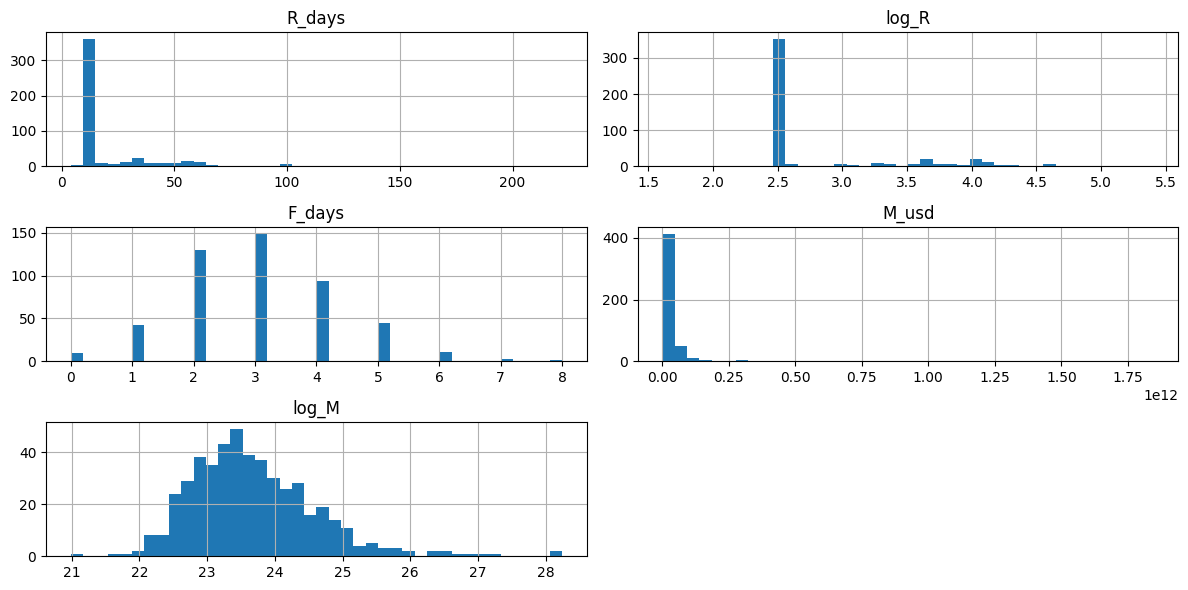

In [49]:
common = feat.index[feat.R_days.notna()]
feat_c = feat.loc[common].copy()
feat_c["log_R"] = np.log1p(feat_c["R_days"])
feat_c["log_M"] = np.log1p(feat_c["M_usd"])
print("Shares in common set:", len(feat_c))
print("Skew before:", feat_c[["R_days", "M_usd"]].skew().round(2).to_dict())
print("Skew after log1p:", feat_c[["log_R", "log_M"]].skew().round(2).to_dict())
X_rr = StandardScaler().fit_transform(feat_c[["mean_weekly_return", "weekly_beta"]])
X_rfm = StandardScaler().fit_transform(feat_c[["log_R", "F_days", "log_M"]])
feat_c[["R_days", "log_R", "F_days", "M_usd", "log_M"]].hist(bins=40, figsize=(12, 6))
plt.tight_layout(); plt.savefig("outputs/rfm_histograms.png", dpi=150); plt.show()

## Tasks 2.2 and 2.3: Ward and K-means clustering

Dendrograms
:These tree diagrams show how Ward's method gradually merges shares into bigger groups. Big vertical jumps suggest natural places to cut, which gives me a first idea of how many clusters might make sense.

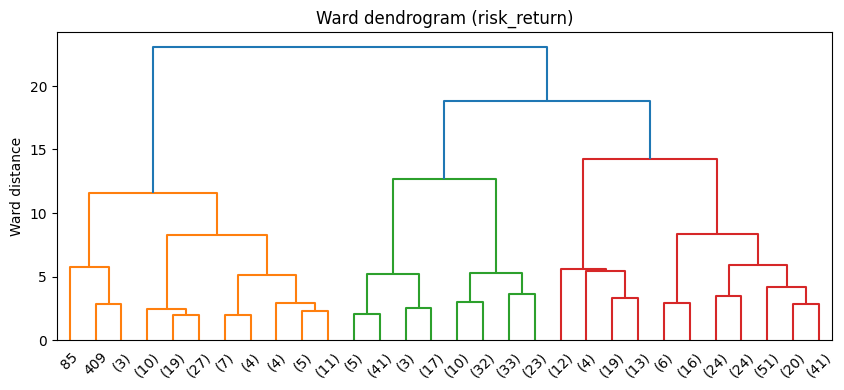

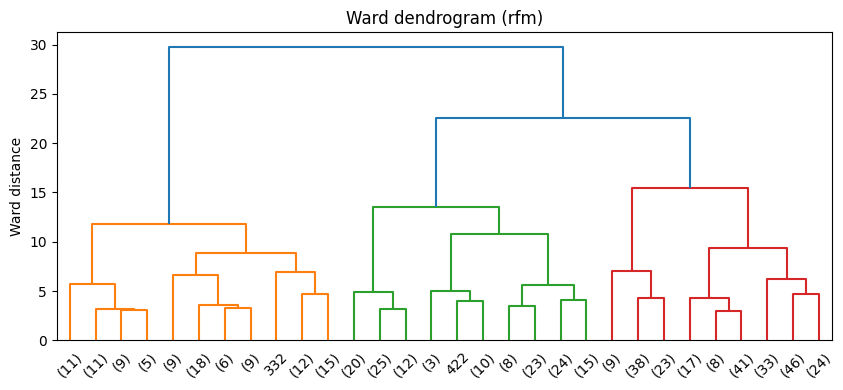

In [50]:
for name, X in [("risk_return", X_rr), ("rfm", X_rfm)]:
    plt.figure(figsize=(10, 4))
    dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=30)
    plt.title(f"Ward dendrogram ({name})"); plt.ylabel("Ward distance")
    plt.savefig(f"outputs/dendrogram_{name}.png", dpi=150, bbox_inches="tight"); plt.show()

How many clusters? I test every option from 2 to 8 clusters with both methods. To compare them, I look at silhouette scores (how well separated the groups are), the K-means elbow chart, and cluster sizes, since a cluster of only a few companies isn't useful. K-means uses a fixed random seed and 20 restarts so the results are stable and repeatable.


,k,ward_sil,ward_sizes,km_sil,km_inertia,km_sizes
0,2,0.339485,"[394, 92]",0.386950,621.634378,"[143, 343]"
1,3,0.273834,"[230, 92, 164]",0.328907,461.178712,"[202, 165, 119]"
2,4,0.282115,"[164, 92, 182, 48]",0.326978,371.577040,"[132, 154, 40, 160]"
3,5,0.304135,"[92, 48, 182, 98, 66]",0.340589,309.613007,"[112, 166, 131, 27, 50]"
4,6,0.320409,"[182, 48, 87, 98, 66, 5]",0.333885,265.448134,"[56, 113, 158, 111, 43, 5]"
5,7,0.323951,"[87, 48, 160, 98, 66, 5, 22]",0.331472,227.476228,"[83, 74, 143, 85, 5, 48, 48]"
6,8,0.320779,"[160, 48, 5, 98, 66, 31, 22, 56]",0.354243,194.361647,"[136, 43, 76, 78, 5, 29, 40, 79]"


,k,ward_sil,ward_sizes,km_sil,km_inertia,km_sizes
0,2,0.402044,"[380, 106]",0.415400,999.520393,"[384, 102]"
1,3,0.335170,"[239, 106, 141]",0.343037,742.493330,"[257, 139, 90]"
2,4,0.292533,"[141, 106, 169, 70]",0.361713,559.243771,"[82, 194, 90, 120]"
3,5,0.285990,"[106, 84, 169, 70, 57]",0.348176,480.744042,"[141, 87, 40, 99, 119]"
4,6,0.276030,"[84, 70, 169, 70, 57, 36]",0.344619,421.194173,"[139, 31, 38, 96, 113, 69]"
5,7,0.296944,"[169, 70, 36, 70, 57, 70, 14]",0.340208,377.582090,"[147, 68, 30, 47, 94, 80, 20]"
6,8,0.299019,"[70, 70, 36, 103, 57, 70, 14, 66]",0.345739,343.636956,"[135, 29, 22, 19, 61, 86, 67, 67]"


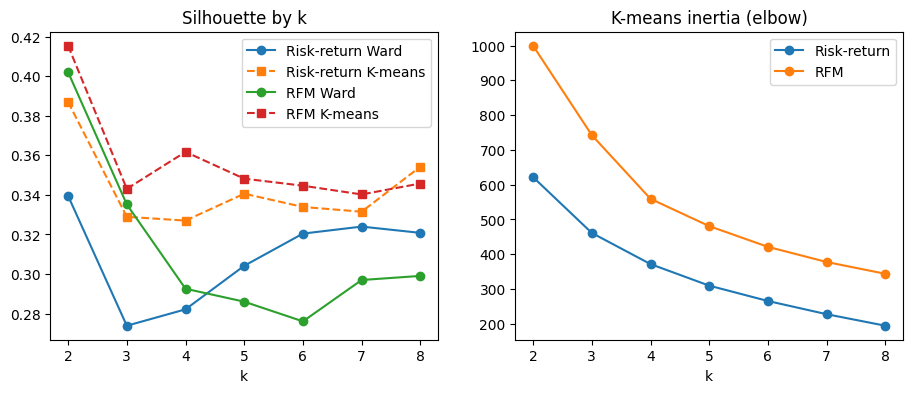

In [51]:
def compare_k(X, name):
    rows = []
    for k in range(2, 9):
        w = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        rows.append({"k": k, "ward_sil": silhouette_score(X, w), "ward_sizes": np.bincount(w).tolist(),
                     "km_sil": silhouette_score(X, km.labels_), "km_inertia": km.inertia_,
                     "km_sizes": np.bincount(km.labels_).tolist()})
    out = pd.DataFrame(rows); out.to_csv(f"outputs/k_selection_{name}.csv", index=False); return out
k_rr, k_rfm = compare_k(X_rr, "risk_return"), compare_k(X_rfm, "rfm")
display(k_rr, k_rfm)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for df, n in [(k_rr, "Risk-return"), (k_rfm, "RFM")]:
    ax[0].plot(df.k, df.ward_sil, "o-", label=f"{n} Ward"); ax[0].plot(df.k, df.km_sil, "s--", label=f"{n} K-means")
    ax[1].plot(df.k, df.km_inertia, "o-", label=n)
ax[0].set(title="Silhouette by k", xlabel="k"); ax[1].set(title="K-means inertia (elbow)", xlabel="k")
ax[0].legend(); ax[1].legend(); plt.savefig("outputs/k_diagnostics.png", dpi=150); plt.show()

## Task 2.4: Cluster profiles and algorithm comparison

Final clusters: With the cluster counts chosen, I run the four final models (Ward and K-means on each feature set) and save which cluster each company ends up in.**bold text**

In [52]:
K_RR, K_RFM = 5, 3
feat_c["ward_rr"] = AgglomerativeClustering(n_clusters=K_RR, linkage="ward").fit_predict(X_rr)
feat_c["km_rr"] = KMeans(n_clusters=K_RR, n_init=20, random_state=42).fit_predict(X_rr)
feat_c["ward_rfm"] = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(X_rfm)
feat_c["km_rfm"] = KMeans(n_clusters=K_RFM, n_init=20, random_state=42).fit_predict(X_rfm)
feat_c.to_csv("outputs/feature_table_with_clusters.csv")

In [53]:
print(feat_c[["ward_rr", "km_rr", "ward_rfm", "km_rfm"]].apply(lambda s: s.value_counts().sort_index().tolist()))

ward_rr       [92, 48, 182, 98, 66]
km_rr       [112, 166, 131, 27, 50]
ward_rfm            [239, 106, 141]
km_rfm               [257, 139, 90]
dtype: object


What the clusters look like:
I describe each cluster in real units, such as typical return, beta, and how actively it trades, so I can give the groups meaningful names. I also use the adjusted Rand index to see how much Ward and K-means agree, which works even though their cluster numbers are arbitrary.

In [54]:
cols = ["mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd"]
for lab in ["ward_rr", "km_rr", "ward_rfm", "km_rfm"]:
    prof = feat_c.groupby(lab)[cols].median().assign(n=feat_c[lab].value_counts())
    prof.to_csv(f"outputs/profile_{lab}.csv"); print(lab); display(prof)
print("ARI Ward vs K-means, risk-return:", adjusted_rand_score(feat_c.ward_rr, feat_c.km_rr))
print("ARI Ward vs K-means, RFM:", adjusted_rand_score(feat_c.ward_rfm, feat_c.km_rfm))

ward_rr


,mean_weekly_return,weekly_beta,R_days,F_days,M_usd,n
ward_rr,,,,,,
0,0.005503,1.217711,11.0,3.0,2.418413e+10,92
1,0.002524,1.513851,11.0,3.0,2.869761e+10,48
2,0.001661,0.964427,11.0,3.0,1.298483e+10,182
3,0.003915,0.666316,11.0,3.0,1.764940e+10,98
4,0.001134,0.448500,11.0,3.0,1.770109e+10,66


km_rr


,mean_weekly_return,weekly_beta,R_days,F_days,M_usd,n
km_rr,,,,,,
0,0.000749,1.031652,11.0,3.0,1.350302e+10,112
1,0.004155,0.996420,11.0,3.0,1.771978e+10,166
2,0.002034,0.530358,11.0,3.0,1.504389e+10,131
3,0.008315,1.449711,11.0,3.0,2.821064e+10,27
4,0.002673,1.543014,11.0,3.0,3.214817e+10,50


ward_rfm


,mean_weekly_return,weekly_beta,R_days,F_days,M_usd,n
ward_rfm,,,,,,
0,0.002448,0.925631,11.0,3.0,1.115361e+10,239
1,0.002625,1.053558,46.5,2.0,1.948502e+10,106
2,0.003260,0.992193,11.0,3.0,4.201310e+10,141


km_rfm


,mean_weekly_return,weekly_beta,R_days,F_days,M_usd,n
km_rfm,,,,,,
0,0.002440,0.927367,11.0,3.0,1.120162e+10,257
1,0.003270,0.993470,11.0,3.0,4.289160e+10,139
2,0.002613,1.046557,53.5,2.0,2.118345e+10,90


ARI Ward vs K-means, risk-return: 0.31833091883680564
ARI Ward vs K-means, RFM: 0.8756259383286987


In [55]:
display(feat_c.groupby("ward_rfm")[["R_days", "F_days", "M_usd"]].mean().round(1))

,R_days,F_days,M_usd
ward_rfm,,,
0,11.1,3.3,1.167656e+10
1,52.4,2.4,4.203975e+10
2,12.0,2.9,8.442218e+10


Plotting the clusters: Risk and return is easy to plot directly: beta along the bottom, average return up the side. RFM has three features, so I use PCA to squash them into two dimensions for a picture. The explained variance tells me how much detail survives that squashing.

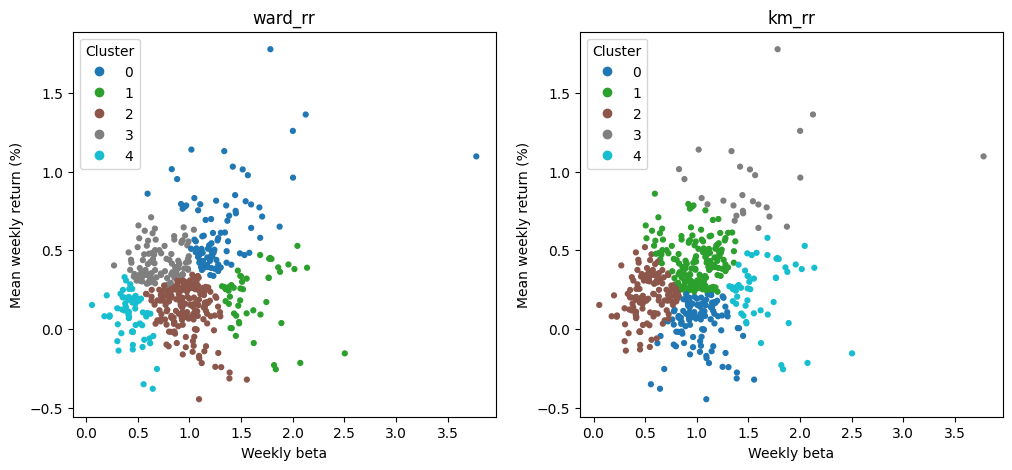

PCA explained variance: [0.43587631 0.3364929 ]


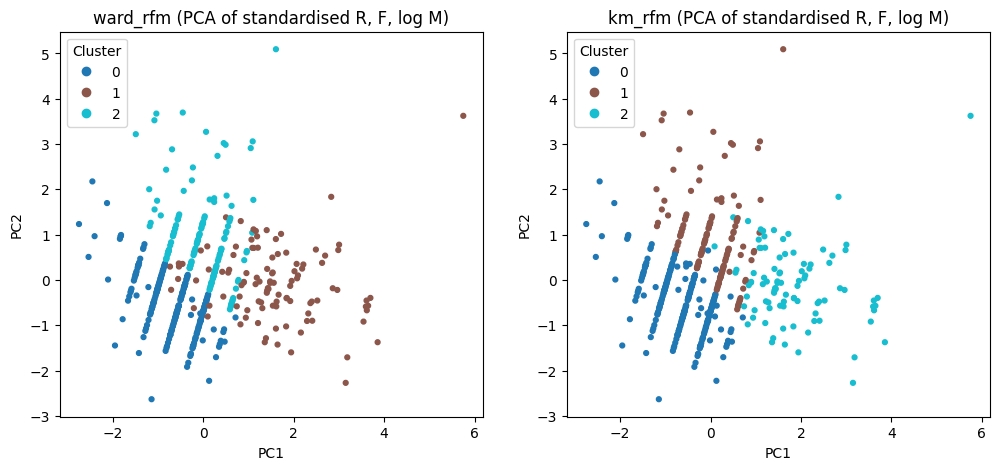

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, lab in zip(ax, ["ward_rr", "km_rr"]):
    sc = a.scatter(feat_c.weekly_beta, feat_c.mean_weekly_return * 100, c=feat_c[lab], cmap="tab10", s=12)
    a.set(xlabel="Weekly beta", ylabel="Mean weekly return (%)", title=lab); a.legend(*sc.legend_elements(), title="Cluster")
plt.savefig("outputs/scatter_risk_return.png", dpi=150); plt.show()
pca = PCA(n_components=2).fit(X_rfm); P = pca.transform(X_rfm)
print("PCA explained variance:", pca.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, lab in zip(ax, ["ward_rfm", "km_rfm"]):
    sc = a.scatter(P[:, 0], P[:, 1], c=feat_c[lab], cmap="tab10", s=12)
    a.set(xlabel="PC1", ylabel="PC2", title=f"{lab} (PCA of standardised R, F, log M)"); a.legend(*sc.legend_elements(), title="Cluster")
plt.savefig("outputs/pca_rfm.png", dpi=150); plt.show()

In [57]:
print("Highest beta:", feat_c.weekly_beta.idxmax(), "| Highest return:", feat_c.mean_weekly_return.idxmax())

Highest beta: CVNA | Highest return: SMCI


## Sector composition (supports Task 3.2.1)



Sector mix: hese charts show which sectors make up each cluster. That lets me see whether, say, tech companies group together on risk but spread out on trading activity.

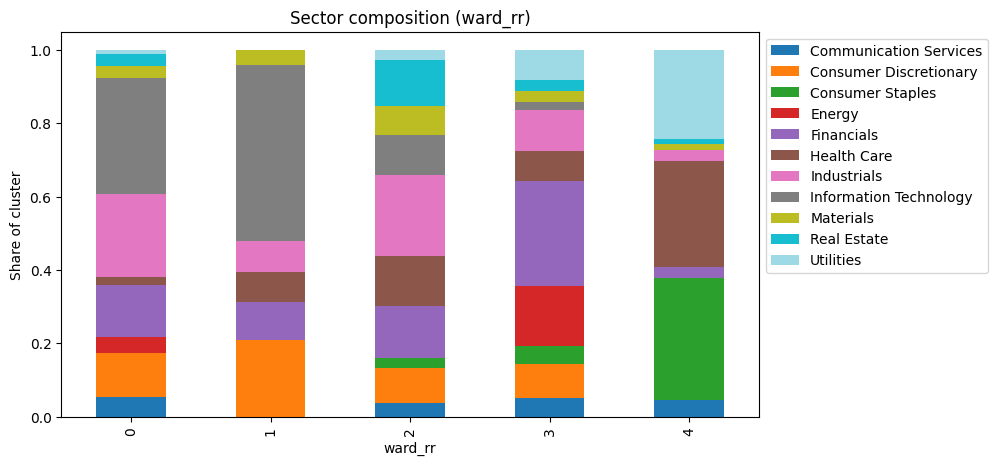

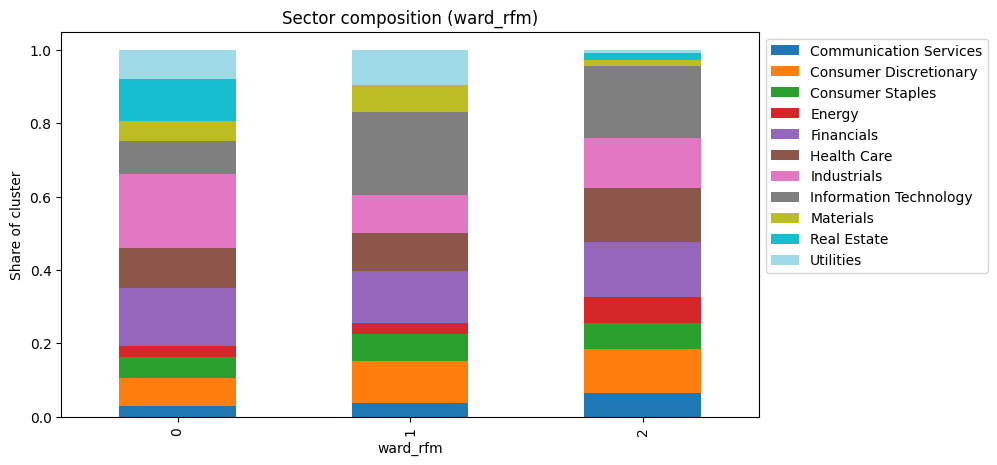

In [58]:
for lab in ["ward_rr", "ward_rfm"]:
    pd.crosstab(feat_c["GICS Sector"], feat_c[lab], normalize="columns").T.plot(
        kind="bar", stacked=True, figsize=(9, 5), colormap="tab20")
    plt.title(f"Sector composition ({lab})"); plt.ylabel("Share of cluster"); plt.legend(bbox_to_anchor=(1, 1))
    plt.savefig(f"outputs/sector_{lab}.png", dpi=150, bbox_inches="tight"); plt.show()

In [59]:
for lab in ["ward_rr", "ward_rfm"]:
    print(lab)
    display((pd.crosstab(feat_c["GICS Sector"], feat_c[lab], normalize="columns") * 100).round(1))

ward_rr


ward_rr,0,1,2,3,4
GICS Sector,,,,,
Communication Services,5.4,0.0,3.8,5.1,4.5
Consumer Discretionary,12.0,20.8,9.3,9.2,0.0
Consumer Staples,0.0,0.0,2.7,5.1,33.3
Energy,4.3,0.0,0.0,16.3,0.0
Financials,14.1,10.4,14.3,28.6,3.0
Health Care,2.2,8.3,13.7,8.2,28.8
Industrials,22.8,8.3,22.0,11.2,3.0
Information Technology,31.5,47.9,11.0,2.0,0.0
Materials,3.3,4.2,7.7,3.1,1.5


ward_rfm


ward_rfm,0,1,2
GICS Sector,,,
Communication Services,2.9,3.8,6.4
Consumer Discretionary,7.5,11.3,12.1
Consumer Staples,5.9,7.5,7.1
Energy,2.9,2.8,7.1
Financials,15.9,14.2,14.9
Health Care,10.9,10.4,14.9
Industrials,20.1,10.4,13.5
Information Technology,9.2,22.6,19.9
Materials,5.4,7.5,1.4


## Task 2.5: RFM sensitivity analysis

Does Monetary matter? First I check how closely R, F and Monetary are related, because related features can end up counting the same information twice. Then I rerun the RFM clustering without Monetary, keeping everything else the same, and see how much the groups change. If the clusters barely move, Monetary wasn't adding much. If they shift a lot, it was doing most of the separating, probably by sorting big, heavily traded companies from smaller ones.

In [60]:
corr = feat_c[["log_R", "F_days", "log_M"]].corr()
corr_s = feat_c[["log_R", "F_days", "log_M"]].corr(method="spearman")
corr.to_csv("outputs/rfm_correlations.csv")
print("Pearson correlations:"); display(corr.round(3))
print("Spearman (rank) correlations:"); display(corr_s.round(3))

X_rf = StandardScaler().fit_transform(feat_c[["log_R", "F_days"]])      # re-standardised afresh
feat_c["ward_rf"] = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(X_rf)
print("ARI, Ward RFM vs Ward R+F only:", adjusted_rand_score(feat_c.ward_rfm, feat_c.ward_rf))
print("Cluster sizes without M:", feat_c.ward_rf.value_counts().sort_index().tolist())
display(pd.crosstab(feat_c.ward_rfm, feat_c.ward_rf, rownames=["with M"], colnames=["without M"]))

prof_cmp = pd.concat({
    "with M": feat_c.groupby("ward_rfm")[["R_days", "F_days", "M_usd"]].median(),
    "without M": feat_c.groupby("ward_rf")[["R_days", "F_days", "M_usd"]].median()})
display(prof_cmp)
feat_c.to_csv("outputs/feature_table_with_clusters.csv")

Pearson correlations:


,log_R,F_days,log_M
log_R,1.000,-0.285,0.127
F_days,-0.285,1.000,0.013
log_M,0.127,0.013,1.000


Spearman (rank) correlations:


,log_R,F_days,log_M
log_R,1.000,-0.196,0.137
F_days,-0.196,1.000,-0.048
log_M,0.137,-0.048,1.000


ARI, Ward RFM vs Ward R+F only: 0.34895470224730957
Cluster sizes without M: [109, 252, 125]


without M,0,1,2
with M,,,
0,0,173,66
1,101,5,0
2,8,74,59


R_days  F_days         M_usd
          ward_rfm                              
with M    0           11.0     3.0  1.115361e+10
          1           46.5     2.0  1.948502e+10
          2           11.0     3.0  4.201310e+10
without M 0           46.0     2.0  2.084781e+10
          1           11.0     4.0  1.473576e+10
          2           11.0     2.0  1.769899e+10

## Exporting


In [61]:
!zip -r cwk1_outputs.zip data outputs
from google.colab import files; files.download("cwk1_outputs.zip")

updating: data/ (stored 0%)
updating: data/metadata.json (deflated 21%)
updating: data/sp500_constituents.csv (deflated 68%)
updating: data/daily_close.csv (deflated 77%)
updating: data/daily_volume.csv (deflated 62%)
updating: data/daily_stock_splits.csv (deflated 99%)
updating: data/benchmark_gspc.csv (deflated 77%)
updating: data/daily_adj_close.csv (deflated 62%)
updating: data/daily_dividends.csv (deflated 98%)
updating: outputs/ (stored 0%)
updating: outputs/profile_ward_rr.csv (deflated 42%)
updating: outputs/sector_ward_rfm.png (deflated 20%)
updating: outputs/rfm_histograms.png (deflated 27%)
updating: outputs/sector_ward_rr.png (deflated 20%)
updating: outputs/pca_rfm.png (deflated 5%)
updating: outputs/profile_km_rr.csv (deflated 41%)
updating: outputs/k_selection_risk_return.csv (deflated 49%)
updating: outputs/inclusion_exclusion_log.csv (deflated 84%)
updating: outputs/profile_km_rfm.csv (deflated 34%)
updating: outputs/dendrogram_risk_return.png (deflated 17%)
updating: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>